# 2.0 Modelado y evaluación – Clasificación del rubro de reclamos de consumidores hipervulnerables

**Proyecto de Aprendizaje Automático – Centro Politécnico Superior Malvinas Argentinas**

## Objetivo

Clasificar el **rubro** de un reclamo de consumidores (variable `rubro_agrupado`, 11 clases) a partir del perfil de la
persona y su provincia, probando Regresión Logística, K-NN y Árbol de Decisión. Es un problema de **clasificación
multiclase**.

## Datos (recordatorio)

Dataset *Programa Consumidores Hipervulnerables* (Datos Argentina, Ministerio de Desarrollo Productivo; licencia
CC BY 4.0). Cada fila es un **reclamo** (denuncia) registrado en la Ventanilla Única Federal de Consumo, entre enero de
2021 y diciembre de 2022: 6.457 reclamos y 8 columnas. El análisis exploratorio y el preprocesamiento están en
`1.0-dm-eda-y-preprocesamiento.ipynb`; el origen y el diccionario, en `docs/01_descripcion_dataset.md`.

## Uso previsto y escenarios

Uso previsto (**supuesto**): clasificar un reclamo cuando se ingresa, antes de conocer su rubro. Se comparan dos
escenarios:

- **Escenario A:** edad, género, provincia **y vulnerabilidad**. Está **condicionado** a que la vulnerabilidad esté
  disponible al ingresar el reclamo, algo que no está confirmado: la ficha dice que el organismo la detecta, sin aclarar
  cuándo ni cómo.
- **Escenario B:** edad, género y provincia (**sin** vulnerabilidad). No depende de ese supuesto.

## Protocolo de evaluación

1. Las clases y los hiperparámetros se definen **solo con el entrenamiento** (validación cruzada de 5 particiones
   estratificadas, con el preprocesamiento **dentro** de cada partición mediante un `Pipeline`).
2. El **modelo final** de cada escenario se elige por el F1 macro medio de la validación cruzada, **antes** de mirar la
   prueba.
3. La prueba se usa **una vez** por modelo, para informar métricas; no se usa para elegir.
4. Se agregan tres comprobaciones: evaluación **temporal** (entrenar con 2021 y evaluar con 2022), **repeticiones** de
   filas idénticas entre conjuntos y **definición de clases** con otros umbrales.

> Los resultados se refieren a los reclamos registrados en el período del dataset y describen qué tan bien el modelo
> anticipa el rubro; **no** permiten afirmar causas ni qué grupos están más expuestos.


In [1]:
# Importaciones. Aquí sí se usan modelos de scikit-learn; el preprocesamiento sale de features.py (el mismo del EDA).
import sys
sys.path.insert(0, "..")  # permite importar el módulo del repositorio desde la carpeta notebooks

from pathlib import Path
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, f1_score, balanced_accuracy_score
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

from consumidores_hipervulnerables.dataset import (
    INTERIM, MODELOS, aplicar_clases, cargar_crudo, clave_fila, definir_clases, etiqueta_estratificacion,
    normalizar, particion_entrenamiento_prueba,
)
from consumidores_hipervulnerables.evaluacion import (
    diferencia_bootstrap, intervalo_bootstrap, por_clase, resumen,
)
from consumidores_hipervulnerables.features import ESCENARIOS, construir_preprocesador

FIG = Path("../reports/figures")
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 60)
warnings.filterwarnings("ignore", category=UserWarning)   # avisos de scikit-learn que no cambian los resultados
SEMILLA = 42  # semilla fija para que todo sea reproducible
# Validación cruzada: 5 particiones estratificadas por clase, mezcladas con semilla fija.
VALIDACION = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

## 1. Datos y partición

Se reconstruye la partición con las mismas funciones del notebook de preprocesamiento (misma semilla) y se comprueba
que coincide con la guardada en `data/interim`. Las clases se definen **con el entrenamiento** y se aplican igual a la
prueba.

In [2]:
# Se parte del archivo original: normalizar -> partición aleatoria estratificada -> clases definidas con el entrenamiento.
df = normalizar(cargar_crudo())
tr, te = particion_entrenamiento_prueba(df, test_size=0.25, semilla=SEMILLA)
clases_propias = definir_clases(tr["rubro"], proporcion_minima=0.015)   # solo con el entrenamiento
tr["rubro_agrupado"] = aplicar_clases(tr["rubro"], clases_propias)
te["rubro_agrupado"] = aplicar_clases(te["rubro"], clases_propias)
CLASES = sorted(tr["rubro_agrupado"].unique())                          # las 11 clases, en orden alfabético

# Comprobación: coincide con la partición y las clases que guardó el notebook 1.0.
guardado = pd.read_csv(INTERIM)
coincide = bool(
    (guardado.loc[tr.index, "rubro_agrupado"].values == tr["rubro_agrupado"].values).all()
    and (guardado.loc[te.index, "rubro_agrupado"].values == te["rubro_agrupado"].values).all()
    and (guardado.loc[tr.index, "particion"] == "entrenamiento").all()
    and (guardado.loc[te.index, "particion"] == "prueba").all()
)
print("Reclamos: entrenamiento =", len(tr), "| prueba =", len(te), "| clases =", len(CLASES))
print("La partición y las clases coinciden con las guardadas en data/interim:", coincide)
pd.DataFrame({"entrenamiento": tr["rubro_agrupado"].value_counts(), "prueba": te["rubro_agrupado"].value_counts()})

Reclamos: entrenamiento = 4842 | prueba = 1615 | clases = 11
La partición y las clases coinciden con las guardadas en data/interim: True


,entrenamiento,prueba
rubro_agrupado,,
Servicios financieros y seguros,1341,447
Servicios de comunicaciones,1042,348
Otros,581,194
Servicios de Salud,555,185
Servicios públicos domiciliarios,466,155
Electrodomésticos y artefactos para el hogar,231,77
Servicios turísticos,184,61
Rodados automotores y embarcaciones,144,48
Servicio de administración de pagos,110,37


## 2. Modelo de referencia (solución sencilla)

La solución más simple es predecir **siempre la clase más frecuente del entrenamiento**. Se evalúa en la prueba con las
**mismas métricas** que los modelos. Su exactitud puede parecer razonable, pero su recall es cero en todas las demás
clases: por eso se evalúa con F1 macro, exactitud balanceada y métricas por clase, y no solo con la exactitud.

In [3]:
# DummyClassifier(strategy='most_frequent'): predice siempre la clase más frecuente del entrenamiento (no usa variables).
referencia = DummyClassifier(strategy="most_frequent").fit(tr[["edad"]], tr["rubro_agrupado"])
pred_ref = referencia.predict(te[["edad"]])
y_te = te["rubro_agrupado"].values
y_tr = tr["rubro_agrupado"].values

print("Clase mayoritaria del entrenamiento:", tr["rubro_agrupado"].value_counts().idxmax())
res_ref = resumen(y_te, pred_ref)
print({k: round(v, 3) for k, v in res_ref.items()})
print()
print("Recall por clase del modelo de referencia (solo la clase mayoritaria tiene recall distinto de 0):")
por_clase(y_te, pred_ref, CLASES)[["recall", "casos"]].round(3)

Clase mayoritaria del entrenamiento: Servicios financieros y seguros
{'exactitud': 0.277, 'exactitud balanceada': 0.091, 'F1 macro': 0.039, 'F1 ponderado': 0.12}

Recall por clase del modelo de referencia (solo la clase mayoritaria tiene recall distinto de 0):


,recall,casos
Electrodomésticos y artefactos para el hogar,0.0,77
Equipos de telefonía,0.0,28
Otros,0.0,194
Rodados automotores y embarcaciones,0.0,48
Servicio de administración de pagos,0.0,37
Servicios de Salud,0.0,185
Servicios de comunicaciones,0.0,348
Servicios de transporte aéreo,0.0,35
Servicios financieros y seguros,1.0,447
Servicios públicos domiciliarios,0.0,155


## 3. Modelos e hiperparámetros (validación cruzada solo con el entrenamiento)

**Modelos y qué se ajusta de cada uno**

| Modelo | Hiperparámetros que se prueban | Tratamiento del desbalance |
|---|---|---|
| Regresión Logística | `C` (fuerza de la regularización) y `class_weight` | `class_weight` (`None` o `balanced`) |
| Árbol de Decisión | `max_depth`, `min_samples_leaf` y `class_weight` | `class_weight` (`None` o `balanced`) |
| K-NN | `n_neighbors` y `weights` | **Sin ponderación de clases**: `KNeighborsClassifier` no tiene `class_weight`. Su parámetro `weights` (`uniform` o `distance`) solo pondera el voto de los vecinos y **no** equivale a ponderar clases |

**Criterio de selección:** F1 macro medio de la validación cruzada (promedia el F1 de cada clase sin ponderar por
tamaño, así que las clases chicas pesan igual que las grandes). **Preprocesamiento:** dentro de un `Pipeline`, por lo
que las categorías y el escalado se aprenden en cada partición solo con sus datos de entrenamiento.

In [4]:
# Grillas de hiperparámetros de cada modelo (ver la tabla de arriba).
MODELOS_GRILLA = {
    "Regresión Logística": (
        LogisticRegression(max_iter=3000),
        {"C": [0.01, 0.1, 1, 10], "class_weight": [None, "balanced"]},
    ),
    "Árbol de Decisión": (
        DecisionTreeClassifier(random_state=SEMILLA),
        {"max_depth": [3, 5, 8, 12, 16, None], "min_samples_leaf": [1, 10, 30], "class_weight": [None, "balanced"]},
    ),
    "K-NN": (
        KNeighborsClassifier(),
        {"n_neighbors": [5, 15, 31, 61], "weights": ["uniform", "distance"]},
    ),
}


def buscar(estimador, grilla, cols, datos, etiquetas, validacion=VALIDACION):
    """Búsqueda de hiperparámetros por validación cruzada con el preprocesamiento DENTRO del Pipeline.

    El Pipeline (preprocesador + modelo) se reajusta en cada partición solo con los datos de entrenamiento de esa
    partición. scoring='f1_macro' elige la combinación con mejor F1 macro medio. refit=True reentrena la mejor sobre
    todo el entrenamiento.
    """
    pipe = Pipeline([
        ("prep", construir_preprocesador(cols["cat"], cols["num"])),
        ("modelo", estimador),
    ])
    grilla_pipe = {f"modelo__{k}": v for k, v in grilla.items()}
    gs = GridSearchCV(pipe, grilla_pipe, scoring="f1_macro", cv=validacion, n_jobs=2, refit=True)
    gs.fit(datos[cols["cat"] + cols["num"]], etiquetas)
    return gs


def correr_busquedas(datos, etiquetas, validacion=VALIDACION):
    """Ejecuta la búsqueda de los tres modelos en los dos escenarios. Devuelve {escenario: {modelo: GridSearchCV}}."""
    return {
        esc: {nombre: buscar(est, grilla, cols, datos, etiquetas, validacion)
              for nombre, (est, grilla) in MODELOS_GRILLA.items()}
        for esc, cols in ESCENARIOS.items()
    }


def tabla_cv(busquedas):
    """Resumen de la validación cruzada: F1 macro medio, desvío y mejores hiperparámetros de cada modelo."""
    filas = []
    for esc, modelos in busquedas.items():
        for nombre, gs in modelos.items():
            i = gs.best_index_
            filas.append({
                "escenario": esc, "modelo": nombre,
                "F1 macro (CV, media)": gs.cv_results_["mean_test_score"][i],
                "desvío entre particiones": gs.cv_results_["std_test_score"][i],
                "mejores hiperparámetros": {k.replace("modelo__", ""): v for k, v in gs.best_params_.items()},
            })
    return pd.DataFrame(filas)


busq = correr_busquedas(tr, y_tr)
cv = tabla_cv(busq)
vista_cv = cv.assign(**{"F1 macro (CV, media)": cv["F1 macro (CV, media)"].round(3),
                        "desvío entre particiones": cv["desvío entre particiones"].round(3)})
with pd.option_context("display.max_colwidth", None):   # mostrar los hiperparámetros completos
    display(vista_cv)

,escenario,modelo,"F1 macro (CV, media)",desvío entre particiones,mejores hiperparámetros
0,A,Regresión Logística,0.213,0.028,"{'C': 0.1, 'class_weight': 'balanced'}"
1,A,Árbol de Decisión,0.201,0.011,"{'class_weight': None, 'max_depth': None, 'min_samples_leaf': 10}"
2,A,K-NN,0.199,0.015,"{'n_neighbors': 15, 'weights': 'distance'}"
3,B,Regresión Logística,0.117,0.009,"{'C': 0.1, 'class_weight': 'balanced'}"
4,B,Árbol de Decisión,0.131,0.004,"{'class_weight': None, 'max_depth': None, 'min_samples_leaf': 1}"
5,B,K-NN,0.128,0.007,"{'n_neighbors': 31, 'weights': 'distance'}"


In [5]:
# Modelo final de cada escenario: el de mayor F1 macro medio en la validación cruzada (decidido SIN mirar la prueba).
finales = {}
for esc in ESCENARIOS:
    sub = cv[cv["escenario"] == esc].sort_values("F1 macro (CV, media)", ascending=False)
    finales[esc] = sub.iloc[0]["modelo"]
    print(f"Escenario {esc}: modelo final = {finales[esc]} (F1 macro CV = {sub.iloc[0]['F1 macro (CV, media)']:.3f})")
print()
print("Referencia para la validación cruzada: F1 macro de predecir siempre la clase mayoritaria =",
      round(f1_score(y_tr, np.repeat(pd.Series(y_tr).value_counts().idxmax(), len(y_tr)), average="macro", zero_division=0), 3),
      "(en entrenamiento)")

Escenario A: modelo final = Regresión Logística (F1 macro CV = 0.213)
Escenario B: modelo final = Árbol de Decisión (F1 macro CV = 0.131)

Referencia para la validación cruzada: F1 macro de predecir siempre la clase mayoritaria = 0.039 (en entrenamiento)


## 4. Evaluación en el conjunto de prueba

Cada modelo ajustado (con sus mejores hiperparámetros) se evalúa **una vez** en la prueba. Además de las métricas
globales se muestra un intervalo aproximado del 95 % obtenido remuestreando los casos de prueba: refleja la
variabilidad por el tamaño de la prueba (1.615 reclamos, y solo 28 en la clase más chica), no la de entrenar con otros
datos.

In [6]:
# Predicciones de cada modelo en la prueba, y métricas globales con intervalo bootstrap para F1 macro.
f1m = lambda a, b: f1_score(a, b, average="macro", zero_division=0)
bal = lambda a, b: balanced_accuracy_score(a, b)

predicciones = {}
filas = [{"escenario": "—", "modelo": "Referencia (clase mayoritaria)", **res_ref,
          "F1 macro IC95%": "(" + ", ".join(f"{v:.3f}" for v in intervalo_bootstrap(y_te, pred_ref, f1m)) + ")"}]
for esc, modelos in busq.items():
    for nombre, gs in modelos.items():
        pred = gs.predict(te[ESCENARIOS[esc]["cat"] + ESCENARIOS[esc]["num"]])
        predicciones[(esc, nombre)] = pred
        filas.append({"escenario": esc, "modelo": nombre, **resumen(y_te, pred),
                      "F1 macro IC95%": "(" + ", ".join(f"{v:.3f}" for v in intervalo_bootstrap(y_te, pred, f1m)) + ")"})
tabla_prueba = pd.DataFrame(filas)
tabla_prueba.round(3)

,escenario,modelo,exactitud,exactitud balanceada,F1 macro,F1 ponderado,F1 macro IC95%
0,—,Referencia (clase mayoritaria),0.277,0.091,0.039,0.120,"(0.037, 0.042)"
1,A,Regresión Logística,0.259,0.245,0.224,0.280,"(0.200, 0.244)"
2,A,Árbol de Decisión,0.370,0.213,0.216,0.332,"(0.192, 0.240)"
3,A,K-NN,0.336,0.212,0.222,0.319,"(0.196, 0.245)"
4,B,Regresión Logística,0.176,0.156,0.123,0.184,"(0.107, 0.139)"
5,B,Árbol de Decisión,0.262,0.132,0.126,0.235,"(0.109, 0.144)"
6,B,K-NN,0.261,0.134,0.130,0.234,"(0.112, 0.148)"


In [7]:
# Cuántos modelos superan al de referencia y de qué manera: diferencia de F1 macro y de exactitud balanceada con IC95%.
filas = []
for (esc, nombre), pred in predicciones.items():
    d_f1 = diferencia_bootstrap(y_te, pred, pred_ref, f1m)
    d_bal = diferencia_bootstrap(y_te, pred, pred_ref, bal)
    filas.append({
        "escenario": esc, "modelo": nombre,
        "Δ F1 macro vs referencia": round(f1m(y_te, pred) - f1m(y_te, pred_ref), 3),
        "IC95% Δ F1 macro": f"({d_f1[0]:.3f}, {d_f1[1]:.3f})",
        "Δ exactitud balanceada": round(bal(y_te, pred) - bal(y_te, pred_ref), 3),
        "IC95% Δ exact. bal.": f"({d_bal[0]:.3f}, {d_bal[1]:.3f})",
    })
pd.DataFrame(filas)

,escenario,modelo,Δ F1 macro vs referencia,IC95% Δ F1 macro,Δ exactitud balanceada,IC95% Δ exact. bal.
0,A,Regresión Logística,0.184,"(0.160, 0.205)",0.154,"(0.125, 0.183)"
1,A,Árbol de Decisión,0.177,"(0.152, 0.201)",0.122,"(0.102, 0.143)"
2,A,K-NN,0.183,"(0.156, 0.206)",0.121,"(0.099, 0.141)"
3,B,Regresión Logística,0.084,"(0.067, 0.100)",0.065,"(0.044, 0.088)"
4,B,Árbol de Decisión,0.087,"(0.070, 0.104)",0.041,"(0.027, 0.056)"
5,B,K-NN,0.090,"(0.072, 0.109)",0.043,"(0.029, 0.058)"


### Modelo final de cada escenario: métricas por clase

Se muestra el modelo elegido por validación cruzada. Una clase con pocos casos de prueba tiene métricas inestables.

In [8]:
# Métricas por clase (precisión, recall, F1) del modelo final de cada escenario, junto al recall de la referencia.
tablas_clase = {}
for esc in ESCENARIOS:
    pred = predicciones[(esc, finales[esc])]
    t = por_clase(y_te, pred, CLASES)
    tablas_clase[esc] = t
    print(f"Escenario {esc} - {finales[esc]}")
    print(t.round(3).sort_values("casos", ascending=False))
    print()

Escenario A - Regresión Logística
                                              precisión  recall     F1  casos
Servicios financieros y seguros                   0.427   0.201  0.274    447
Servicios de comunicaciones                       0.329   0.322  0.326    348
Otros                                             0.147   0.052  0.076    194
Servicios de Salud                                0.831   0.665  0.739    185
Servicios públicos domiciliarios                  0.254   0.110  0.153    155
Electrodomésticos y artefactos para el hogar      0.068   0.273  0.109     77
Servicios turísticos                              0.156   0.164  0.160     61
Rodados automotores y embarcaciones               0.074   0.333  0.122     48
Servicio de administración de pagos               0.035   0.108  0.053     37
Servicios de transporte aéreo                     0.389   0.400  0.394     35
Equipos de telefonía                              0.045   0.071  0.056     28

Escenario B - Árbol de Decisi

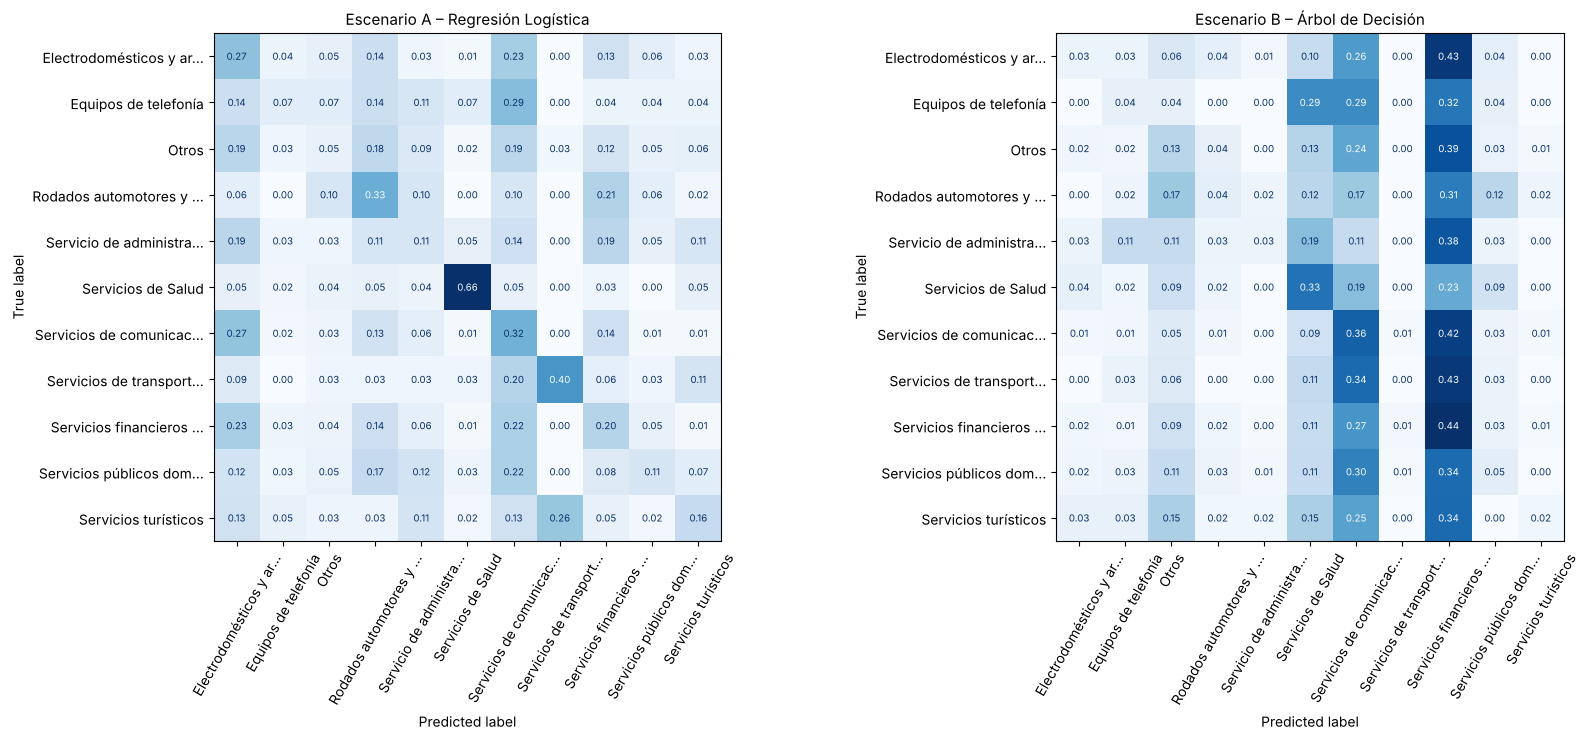

In [9]:
# Matrices de confusión normalizadas por fila (cada fila suma 1): qué clase predice el modelo para los reclamos
# que realmente son de cada rubro. La diagonal es el recall de cada clase.
etiquetas_cortas = {c: (c[:22] + "…" if len(c) > 23 else c) for c in CLASES}
fig, axs = plt.subplots(1, 2, figsize=(17, 7.5))
for ax, esc in zip(axs, ESCENARIOS):
    pred = predicciones[(esc, finales[esc])]
    disp = ConfusionMatrixDisplay.from_predictions(
        y_te, pred, labels=CLASES, normalize="true", display_labels=[etiquetas_cortas[c] for c in CLASES],
        ax=ax, xticks_rotation=60, colorbar=False, values_format=".2f", cmap="Blues")
    ax.set_title(f"Escenario {esc} – {finales[esc]}", fontsize=11)
    for t in ax.texts:
        t.set_fontsize(7)
plt.tight_layout()
plt.savefig(FIG / "05_matrices_confusion.png", dpi=150)
plt.show()

## 5. ¿Cuánto aporta la vulnerabilidad? (escenario A frente a B)

Se compara el modelo final del escenario A con el del escenario B sobre los mismos casos de prueba, con la diferencia
y su intervalo. Si el intervalo incluye el 0, con este tamaño de prueba no se puede afirmar que uno sea mejor que el
otro. **Aunque A rinda más, eso no valida su uso**: depende de que la vulnerabilidad esté disponible al ingresar el
reclamo, algo que hay que confirmar con la fuente.

In [10]:
# Diferencia A - B en F1 macro y exactitud balanceada, apareada (mismos casos de prueba).
pa, pb = predicciones[("A", finales["A"])], predicciones[("B", finales["B"])]
comparacion = []
for nombre, fn in [("F1 macro", f1m), ("Exactitud balanceada", bal)]:
    lo, hi = diferencia_bootstrap(y_te, pa, pb, fn)
    comparacion.append({"métrica": nombre, "A": round(fn(y_te, pa), 3), "B": round(fn(y_te, pb), 3),
                        "A − B": round(fn(y_te, pa) - fn(y_te, pb), 3), "IC95% de A − B": f"({lo:.3f}, {hi:.3f})"})
pd.DataFrame(comparacion)

,métrica,A,B,A − B,IC95% de A − B
0,F1 macro,0.224,0.126,0.097,"(0.070, 0.122)"
1,Exactitud balanceada,0.245,0.132,0.113,"(0.082, 0.145)"


In [11]:
# ¿En qué clases cambia el recall entre A y B? Ayuda a ver si la vulnerabilidad ayuda sobre todo a algún rubro.
dif = pd.DataFrame({"recall A": tablas_clase["A"]["recall"], "recall B": tablas_clase["B"]["recall"],
                    "casos": tablas_clase["A"]["casos"]})
dif["A − B"] = dif["recall A"] - dif["recall B"]
dif.round(3).sort_values("A − B", ascending=False)

,recall A,recall B,casos,A − B
Servicios de transporte aéreo,0.400,0.000,35,0.400
Servicios de Salud,0.665,0.330,185,0.335
Rodados automotores y embarcaciones,0.333,0.042,48,0.292
Electrodomésticos y artefactos para el hogar,0.273,0.026,77,0.247
Servicios turísticos,0.164,0.016,61,0.148
Servicio de administración de pagos,0.108,0.027,37,0.081
Servicios públicos domiciliarios,0.110,0.045,155,0.065
Equipos de telefonía,0.071,0.036,28,0.036
Servicios de comunicaciones,0.322,0.359,348,-0.037
Otros,0.052,0.129,194,-0.077


## 6. Evaluación temporal complementaria: entrenar con 2021 y evaluar con 2022

La partición aleatoria evalúa reclamos de una distribución parecida a la histórica, pero **no comprueba** que el modelo
funcione con reclamos de períodos posteriores. Aunque el modelo no use el tiempo como predictora, podría aplicarse a
reclamos futuros. Acá se entrena con los reclamos de 2021 y se evalúa con los de 2022, definiendo las clases y los
hiperparámetros **solo con 2021**.

**Limitación:** la fecha del dataset es la de *tratamiento*, no necesariamente la de ingreso; por eso 2021 y 2022 son
períodos de tratamiento y esta evaluación es una aproximación a la generalización hacia el futuro.

In [12]:
# Partición temporal: entrenamiento = reclamos tratados en 2021; prueba = reclamos tratados en 2022.
t_tr = df[df["anio"] == 2021].copy()
t_te = df[df["anio"] == 2022].copy()
# Clases definidas SOLO con 2021 (misma regla: al menos 1,5 % de los reclamos de entrenamiento).
clases_2021 = definir_clases(t_tr["rubro"], proporcion_minima=0.015)
t_tr["rubro_agrupado"] = aplicar_clases(t_tr["rubro"], clases_2021)
t_te["rubro_agrupado"] = aplicar_clases(t_te["rubro"], clases_2021)
CLASES_T = sorted(t_tr["rubro_agrupado"].unique())
print("Reclamos: 2021 =", len(t_tr), "| 2022 =", len(t_te), "| clases propias (2021):", len(clases_2021), "+ Otros")
print("Clases definidas con 2021 que difieren de las de la partición aleatoria:",
      sorted(set(clases_2021) ^ set(clases_propias)) or "ninguna")
comp = pd.DataFrame({"2021 (entrenamiento)": t_tr["rubro_agrupado"].value_counts(normalize=True),
                     "2022 (prueba)": t_te["rubro_agrupado"].value_counts(normalize=True)}).fillna(0)
(comp * 100).round(1)

Reclamos: 2021 = 3086 | 2022 = 3371 | clases propias (2021): 10 + Otros
Clases definidas con 2021 que difieren de las de la partición aleatoria: ninguna


,2021 (entrenamiento),2022 (prueba)
rubro_agrupado,,
Electrodomésticos y artefactos para el hogar,4.2,5.3
Equipos de telefonía,1.9,1.5
Otros,13.1,11.0
Rodados automotores y embarcaciones,2.9,3.0
Servicio de administración de pagos,1.9,2.6
Servicios de Salud,12.0,10.9
Servicios de comunicaciones,19.4,23.5
Servicios de transporte aéreo,1.7,2.6
Servicios financieros y seguros,26.6,28.7


In [13]:
# Búsqueda de hiperparámetros con validación cruzada dentro de 2021 y evaluación en 2022.
yt_tr, yt_te = t_tr["rubro_agrupado"].values, t_te["rubro_agrupado"].values
busq_t = correr_busquedas(t_tr, yt_tr)
cv_t = tabla_cv(busq_t)
referencia_t = DummyClassifier(strategy="most_frequent").fit(t_tr[["edad"]], yt_tr)
pred_ref_t = referencia_t.predict(t_te[["edad"]])

filas = [{"escenario": "—", "modelo": "Referencia (clase mayoritaria 2021)", **resumen(yt_te, pred_ref_t)}]
pred_t = {}
for esc, modelos in busq_t.items():
    for nombre, gs in modelos.items():
        p = gs.predict(t_te[ESCENARIOS[esc]["cat"] + ESCENARIOS[esc]["num"]])
        pred_t[(esc, nombre)] = p
        filas.append({"escenario": esc, "modelo": nombre, **resumen(yt_te, p)})
print("Modelo con mejor F1 macro en validación cruzada dentro de 2021 (por escenario):")
for esc in ESCENARIOS:
    sub = cv_t[cv_t["escenario"] == esc].sort_values("F1 macro (CV, media)", ascending=False)
    print(" ", esc, "->", sub.iloc[0]["modelo"], round(sub.iloc[0]["F1 macro (CV, media)"], 3))
pd.DataFrame(filas).round(3)

Modelo con mejor F1 macro en validación cruzada dentro de 2021 (por escenario):
  A -> K-NN 0.22
  B -> K-NN 0.141


,escenario,modelo,exactitud,exactitud balanceada,F1 macro,F1 ponderado
0,—,Referencia (clase mayoritaria 2021),0.287,0.091,0.041,0.128
1,A,Regresión Logística,0.353,0.182,0.182,0.310
2,A,Árbol de Decisión,0.316,0.171,0.179,0.296
3,A,K-NN,0.308,0.177,0.187,0.298
4,B,Regresión Logística,0.212,0.149,0.119,0.191
5,B,Árbol de Decisión,0.239,0.113,0.106,0.219
6,B,K-NN,0.248,0.113,0.106,0.223


In [14]:
# Comparación de las métricas del modelo final de cada escenario: partición aleatoria frente a evaluación temporal.
filas = []
for esc in ESCENARIOS:
    sub = cv_t[cv_t["escenario"] == esc].sort_values("F1 macro (CV, media)", ascending=False)
    nombre_t = sub.iloc[0]["modelo"]
    r_alea = resumen(y_te, predicciones[(esc, finales[esc])])
    r_temp = resumen(yt_te, pred_t[(esc, nombre_t)])
    filas.append({"escenario": esc, "evaluación": "aleatoria 75/25", "modelo": finales[esc],
                  "F1 macro": r_alea["F1 macro"], "exactitud balanceada": r_alea["exactitud balanceada"]})
    filas.append({"escenario": esc, "evaluación": "temporal 2021→2022", "modelo": nombre_t,
                  "F1 macro": r_temp["F1 macro"], "exactitud balanceada": r_temp["exactitud balanceada"]})
pd.DataFrame(filas).round(3)

,escenario,evaluación,modelo,F1 macro,exactitud balanceada
0,A,aleatoria 75/25,Regresión Logística,0.224,0.245
1,A,temporal 2021→2022,K-NN,0.187,0.177
2,B,aleatoria 75/25,Árbol de Decisión,0.126,0.132
3,B,temporal 2021→2022,K-NN,0.106,0.113


## 7. Sensibilidad a las repeticiones: filas idénticas juntas al separar

En el notebook 1.0 se midió que 64 reclamos de prueba tienen una fila completa idéntica en el entrenamiento. Acá se
repite la evaluación **manteniendo juntas las filas idénticas** (todas del mismo lado de la partición) y se compara. Esto
**no identifica personas** ni elimina toda posible dependencia entre reclamos: dos reclamos con el mismo perfil no son
necesariamente de la misma persona.

In [15]:
# StratifiedGroupKFold(n_splits=4): una de las 4 partes (~25 %) es la prueba. groups = clave de la fila completa,
# así que todas las filas idénticas quedan del mismo lado. Se estratifica por rubro (raros agrupados solo para esto).
grupos = clave_fila(df).values
estrat = etiqueta_estratificacion(df["rubro"]).values
sgkf = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEMILLA)
idx_tr, idx_te = next(sgkf.split(df, estrat, groups=grupos))
g_tr, g_te = df.iloc[idx_tr].copy(), df.iloc[idx_te].copy()

repetidas = int(clave_fila(g_te).isin(set(clave_fila(g_tr))).sum())
print("Reclamos: entrenamiento =", len(g_tr), "| prueba =", len(g_te), f"({len(g_te) / len(df):.1%})")
print("Reclamos de prueba con fila idéntica en entrenamiento:", repetidas, "(debe ser 0)")
cl_g = definir_clases(g_tr["rubro"], proporcion_minima=0.015)
g_tr["rubro_agrupado"] = aplicar_clases(g_tr["rubro"], cl_g)
g_te["rubro_agrupado"] = aplicar_clases(g_te["rubro"], cl_g)
print("Clases propias con esta partición:", len(cl_g))

Reclamos: entrenamiento = 4842 | prueba = 1615 (25.0%)
Reclamos de prueba con fila idéntica en entrenamiento: 0 (debe ser 0)
Clases propias con esta partición: 10


In [16]:
# Se reentrena el MODELO FINAL de cada escenario con los mismos hiperparámetros elegidos antes (para aislar el efecto
# de la partición) y se evalúa en esta prueba sin repeticiones cruzadas.
yg_tr, yg_te = g_tr["rubro_agrupado"].values, g_te["rubro_agrupado"].values
filas = []
for esc, cols in ESCENARIOS.items():
    nombre = finales[esc]
    est, _ = MODELOS_GRILLA[nombre]
    params = {k.replace("modelo__", ""): v for k, v in busq[esc][nombre].best_params_.items()}
    pipe = Pipeline([("prep", construir_preprocesador(cols["cat"], cols["num"])), ("modelo", clone(est).set_params(**params))])
    pipe.fit(g_tr[cols["cat"] + cols["num"]], yg_tr)
    r_g = resumen(yg_te, pipe.predict(g_te[cols["cat"] + cols["num"]]))
    r_ref = resumen(yg_te, DummyClassifier(strategy="most_frequent").fit(g_tr[["edad"]], yg_tr).predict(g_te[["edad"]]))
    r_o = resumen(y_te, predicciones[(esc, nombre)])
    filas.append({"escenario": esc, "modelo": nombre,
                  "F1 macro (partición original)": r_o["F1 macro"], "F1 macro (filas idénticas juntas)": r_g["F1 macro"],
                  "exact. balanceada (original)": r_o["exactitud balanceada"],
                  "exact. balanceada (idénticas juntas)": r_g["exactitud balanceada"],
                  "F1 macro de la referencia (esta prueba)": r_ref["F1 macro"]})
pd.DataFrame(filas).round(3)

,escenario,modelo,F1 macro (partición original),F1 macro (filas idénticas juntas),exact. balanceada (original),exact. balanceada (idénticas juntas),F1 macro de la referencia (esta prueba)
0,A,Regresión Logística,0.224,0.209,0.245,0.232,0.039
1,B,Árbol de Decisión,0.126,0.136,0.132,0.136,0.039


## 8. Sensibilidad a la definición de las clases

Cambiar el umbral de rubros que se conservan **cambia el problema**: con más clases propias la tarea es más
difícil; con menos, se simplifica. Por eso no se compara la métrica «cruda»: cada variante se compara con **su propio
modelo de referencia**, y se informa cuánto supera el modelo a esa referencia. Los hiperparámetros se mantienen los del
modelo final para aislar el efecto de las clases.

In [17]:
# Se define la lista de clases con otras proporciones (SOLO con el entrenamiento) y se reentrena el modelo final.
filas = []
for prop in [0.01, 0.015, 0.02]:
    cl = definir_clases(tr["rubro"], proporcion_minima=prop)
    ytr_v = aplicar_clases(tr["rubro"], cl).values
    yte_v = aplicar_clases(te["rubro"], cl).values
    for esc, cols in ESCENARIOS.items():
        nombre = finales[esc]
        est, _ = MODELOS_GRILLA[nombre]
        params = {k.replace("modelo__", ""): v for k, v in busq[esc][nombre].best_params_.items()}
        pipe = Pipeline([("prep", construir_preprocesador(cols["cat"], cols["num"])), ("modelo", clone(est).set_params(**params))])
        pipe.fit(tr[cols["cat"] + cols["num"]], ytr_v)
        pred_v = pipe.predict(te[cols["cat"] + cols["num"]])
        ref_v = DummyClassifier(strategy="most_frequent").fit(tr[["edad"]], ytr_v).predict(te[["edad"]])
        filas.append({"proporción mínima": f"{prop:.1%}", "clases (con Otros)": len(cl) + 1, "escenario": esc,
                      "modelo": nombre, "F1 macro": f1m(yte_v, pred_v), "F1 macro referencia": f1m(yte_v, ref_v),
                      "ganancia sobre la referencia": f1m(yte_v, pred_v) - f1m(yte_v, ref_v)})
pd.DataFrame(filas).round(3)

,proporción mínima,clases (con Otros),escenario,modelo,F1 macro,F1 macro referencia,ganancia sobre la referencia
0,1.0%,14,A,Regresión Logística,0.170,0.031,0.139
1,1.0%,14,B,Árbol de Decisión,0.098,0.031,0.067
2,1.5%,11,A,Regresión Logística,0.224,0.039,0.184
3,1.5%,11,B,Árbol de Decisión,0.126,0.039,0.087
4,2.0%,10,A,Regresión Logística,0.241,0.043,0.197
5,2.0%,10,B,Árbol de Decisión,0.134,0.043,0.090


## 9. Uso del modelo: predicción de ejemplo y modelos guardados

Se guarda cada modelo final como un `Pipeline` completo (preprocesador + modelo, ajustado con todo el entrenamiento)
para clasificar reclamos nuevos de la misma manera que en el entrenamiento. Como ejemplo, se clasifican dos reclamos
hipotéticos; el resultado ilustra cómo se usa `predict` y `predict_proba`, no es un caso real.

In [18]:
# Se guardan los modelos finales (Pipeline completo) en models/ para poder cargarlos y predecir con reclamos nuevos.
for esc in ESCENARIOS:
    joblib.dump(busq[esc][finales[esc]].best_estimator_, MODELOS / f"modelo_final_escenario_{esc}.joblib")

# Dos reclamos hipotéticos (no son datos reales).
nuevos = pd.DataFrame([
    {"vulnerabilidad": "Adulto/a mayor", "genero": "Femenino", "provincia_consumidor": "Córdoba", "edad": 72},
    {"vulnerabilidad": "Turista", "genero": "Masculino", "provincia_consumidor": "Ciudad Autónoma de Buenos Aires", "edad": 35},
])
for esc, cols in ESCENARIOS.items():
    modelo = joblib.load(MODELOS / f"modelo_final_escenario_{esc}.joblib")   # se vuelve a cargar para comprobar que funciona
    X_nuevo = nuevos[cols["cat"] + cols["num"]]
    prob = pd.DataFrame(modelo.predict_proba(X_nuevo), columns=modelo.classes_)
    print(f"Escenario {esc} ({finales[esc]})")
    for i in range(len(nuevos)):
        top = prob.iloc[i].sort_values(ascending=False).head(3)
        print(f"  Reclamo {i + 1}: predicción = {modelo.predict(X_nuevo)[i]} | tres clases más probables:",
              "; ".join(f"{k} ({v:.2f})" for k, v in top.items()))

Escenario A (Regresión Logística)
  Reclamo 1: predicción = Servicios financieros y seguros | tres clases más probables: Servicios financieros y seguros (0.20); Servicios de comunicaciones (0.15); Otros (0.10)
  Reclamo 2: predicción = Servicios de transporte aéreo | tres clases más probables: Servicios de transporte aéreo (0.47); Servicios turísticos (0.32); Otros (0.05)
Escenario B (Árbol de Decisión)
  Reclamo 1: predicción = Otros | tres clases más probables: Otros (0.33); Servicios financieros y seguros (0.33); Servicios de comunicaciones (0.33)
  Reclamo 2: predicción = Servicios financieros y seguros | tres clases más probables: Servicios financieros y seguros (0.45); Servicios de comunicaciones (0.18); Electrodomésticos y artefactos para el hogar (0.09)


**Cómo leer el ejemplo.** Las probabilidades de `predict_proba` indican qué tan seguro está el modelo; no son
frecuencias reales. En el escenario B el modelo final es un árbol muy profundo (36 niveles y 970 hojas). Para el
primer reclamo, la hoja a la que llega contiene 3 reclamos de entrenamiento con exactamente el mismo género,
provincia y edad, de rubros distintos; por eso las tres clases reciben la misma probabilidad (0,33) y la predicción
(`Otros`) sale de un desempate. Es una predicción poco confiable, no una conclusión.

## 10. Resumen e interpretación

Todas las cifras salen de las tablas de este notebook (semilla 42). Las explicaciones de por qué ocurre algo se
presentan como **hipótesis**: con estos datos no se pueden comprobar.

**Resultados**
- Los tres modelos superan claramente al modelo de referencia en F1 macro (referencia 0,039): en el escenario A
  quedan alrededor de 0,21-0,22 y en el B, alrededor de 0,12-0,13. En términos absolutos son valores bajos: la
  mayoría de las clases tiene F1 menor a 0,2.
- La exactitud sola engaña: la regresión logística del escenario A tiene exactitud 0,259, **menor** que la del modelo
  de referencia (0,277), pero una exactitud balanceada de 0,245 frente a 0,091.
- Las diferencias entre los tres modelos son pequeñas frente a la variabilidad (desvío entre particiones de la validación
  cruzada y intervalos de la prueba): no hay evidencia para afirmar que uno sea claramente mejor. La elección del modelo
  final se hizo con una regla fijada de antemano (mayor F1 macro en validación cruzada).
- La vulnerabilidad mejora el F1 macro en unos 0,10 puntos (A − B), sobre todo en transporte aéreo, Salud y
  rodados; el escenario B casi no identifica las clases chicas.
- Con evaluación temporal (2021 → 2022) los resultados son algo menores que con la partición aleatoria.
- Al mantener juntas las filas idénticas el F1 macro cambia poco y en distinta dirección según el escenario, así que
  no hay evidencia de que las repeticiones inflaran el resultado.
- Con otros umbrales de clases la ganancia sobre la referencia crece al bajar la cantidad de clases: es coherente con
  que la tarea se simplifica, no con que el modelo mejore.

**Hipótesis**
- Que la vulnerabilidad aporte tanto en Salud y transporte aéreo podría deberse a que se registra a partir de la
  situación que originó el reclamo. Si fuera así, el escenario A no estaría disponible en el momento de ingreso. No se
  puede confirmar sin información del organismo.
- Que el perfil y la provincia anticipen poco el rubro podría deberse a que el rubro depende sobre todo de lo que la
  persona consumió, información que el dataset no contiene.

**Límites:** reclamos registrados de 2021-2022 (no representan a quienes no reclamaron); fecha de tratamiento, no de
ingreso; no hay identificador de persona ni diccionario con descripciones; clases chicas con 28 a 48 casos de prueba;
`Otros` agrupa 37 rubros.